In [36]:
import numpy as np
from scipy.stats import binom
import matplotlib.pyplot as plt

def calc_metrics(est, real):
    bias = est.mean() - real
    var = est.var()
    mse = bias**2 + var
    return bias, var, mse

In [40]:
M = 10000
B = 5
ps = [0.1, 0.3, 0.5, 0.7, 0.9]
ns = [20, 50, 100]

def g(p):
    return binom.sf(2, B, p)  # P(X >= 3)

res = {}   # (n, p) -> (bias, var, mse)
ests = {}  # (n, p) -> M wartości estymatora

for n in ns:
    for p in ps:
        x = np.random.binomial(B, p, size=(M, n))
        est = g(x.mean(axis=1) / B)
        ests[(n, p)] = est
        res[(n, p)] = calc_metrics(est, g(p))

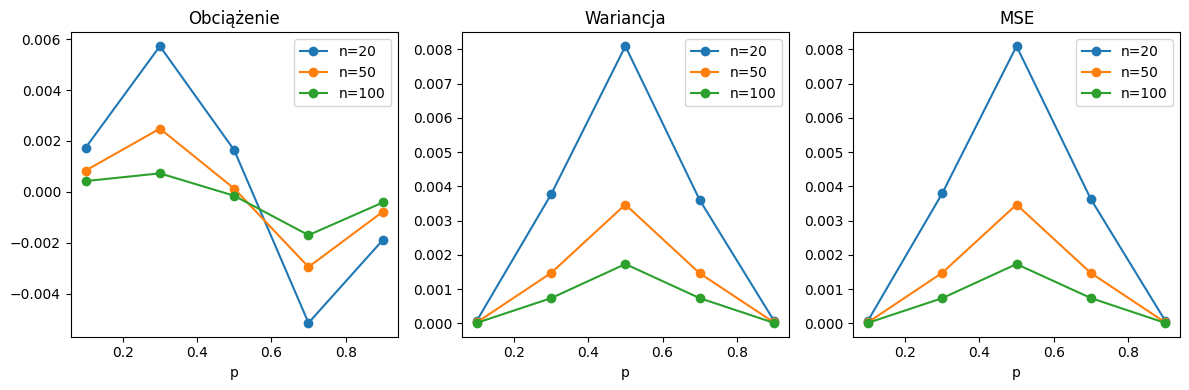

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, title in enumerate(["Obciążenie", "Wariancja", "MSE"]):
    for n in ns:
        axes[i].plot(ps, [res[(n, p)][i] for p in ps], marker="o", label=f"n={n}")
    axes[i].set_title(title)
    axes[i].set_xlabel("p")
    axes[i].legend()
plt.tight_layout()
plt.show()

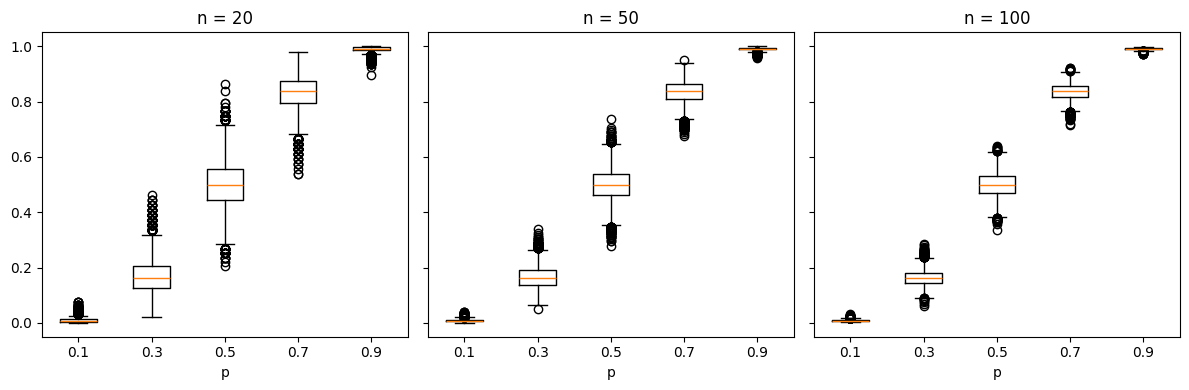

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, n in zip(axes, ns):
    ax.boxplot([ests[(n, p)] for p in ps], tick_labels=ps)
    ax.set_title(f"n = {n}")
    ax.set_xlabel("p")
plt.tight_layout()
plt.show()